# Task 1 · Predicting House Prices with Linear Regression

**Objective:** Build and evaluate a linear regression model that predicts house prices (`SalePrice`) from features such as area, location (neighbourhood), number of rooms and age, covering the full workflow from data cleaning to model interpretation.

**Dataset:** `train.csv` (Ames Housing, 1,460 houses, 80 features).

**Setup:** put `train.csv` in the same folder as this notebook and run `pip install -r req.txt`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

## 1. Load data and exploratory data analysis (EDA)

In [2]:
df = pd.read_csv("train.csv")
print("Shape:", df.shape)
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.1 Null check

In [3]:
nulls = df.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
null_report = pd.DataFrame({"missing": nulls, "percent": (nulls / len(df) * 100).round(1)})
print(f"{len(null_report)} columns contain missing values")
null_report

19 columns contain missing values


,missing,percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


**Reading the nulls:** in this dataset most "missing" values are not errors. A blank in `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*` or `MasVnrType` means the house **does not have** that feature (no pool, no alley, no garage and so on). Only `LotFrontage`, `MasVnrArea`, `GarageYrBlt` and `Electrical` are genuine gaps. This drives the cleaning strategy in section 3.

### 1.2 Descriptive statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


### 1.3 Distribution of the target variable (price)

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.88


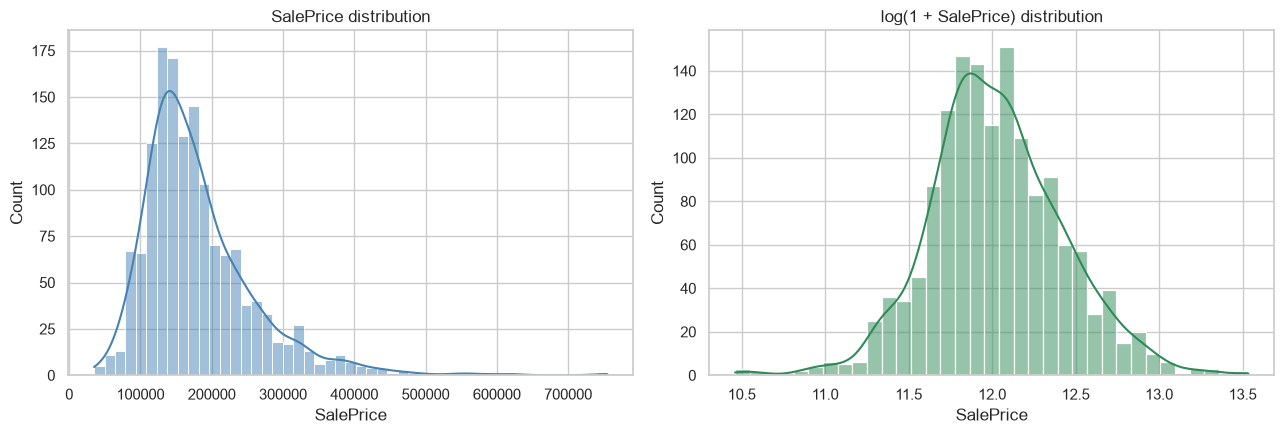

In [5]:
print(df["SalePrice"].describe())
print(f"\nSkewness: {df['SalePrice'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("SalePrice distribution")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("log(1 + SalePrice) distribution")
plt.tight_layout()
plt.show()

Prices are **right-skewed** (a few expensive houses pull the tail out). Linear regression works on the raw price, as the task requires, but this skew is one reason a handful of expensive houses will be predicted less accurately.

## 2. Feature selection discussion

Which features are likely to predict price, and why:

| Group | Features | Reasoning |
|---|---|---|
| **Size / area** | `GrLivArea`, `TotalBsmtSF`, `LotArea`, `GarageArea`, `MasVnrArea` | Buyers pay per square foot; living area is usually the strongest single driver. |
| **Quality & condition** | `OverallQual`, `OverallCond`, `ExterQual`, `KitchenQual`, `BsmtQual`, `HeatingQC` | Finish quality commands a premium independent of size. |
| **Location** | `Neighborhood`, `MSZoning`, `Condition1` | Same house, different neighbourhood, different price. One-hot encoded. |
| **Rooms** | `BedroomAbvGr`, `TotRmsAbvGrd`, `TotalBath` (engineered), `Fireplaces`, `GarageCars` | Capacity and amenities. |
| **Age** | `HouseAge` (= `YrSold` - `YearBuilt`), `RemodAge` (= `YrSold` - `YearRemodAdd`) | Newer or recently renovated homes sell for more. Age is more informative than the raw year. |

**Feature engineering and clean-up decisions**
- Created `HouseAge`, `RemodAge` and `TotalBath` (full baths plus half of half-baths, basement baths included).
- Dropped `Id` (just a row label).
- Dropped exactly-redundant columns to avoid perfect multicollinearity, which makes linear coefficients unstable: `1stFlrSF`, `2ndFlrSF`, `LowQualFinSF` (they add up to `GrLivArea`) and `BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF` (they add up to `TotalBsmtSF`).
- Dropped `YearBuilt`, `YearRemodAdd` and `YrSold` (replaced by the age features) and `GarageYrBlt` (nearly identical to `YearBuilt` and null for houses without a garage).
- Dropped the original bath columns (merged into `TotalBath`).
- Dropped columns that are >90% "feature absent" (`PoolQC`, `MiscFeature`, `Alley`): too little variation to learn from.

## 3. Handle missing values and encode categorical features

In [6]:
data = df.copy()

# --- Feature engineering -----------------------------------------------------
data["HouseAge"] = data["YrSold"] - data["YearBuilt"]
data["RemodAge"] = data["YrSold"] - data["YearRemodAdd"]
data["TotalBath"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                     + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])

drop_cols = [
    "Id",
    "YearBuilt", "YearRemodAdd", "YrSold", "GarageYrBlt",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath",
    "PoolQC", "MiscFeature", "Alley",
]
data = data.drop(columns=drop_cols)

# --- Missing values: structural 'None' (feature absent) -----------------------
cat_cols_all = data.select_dtypes(exclude="number").columns.drop("SalePrice", errors="ignore")
for col in cat_cols_all:
    if col == "Electrical":
        data[col] = data[col].fillna(data[col].mode()[0])   # 1 genuine gap
    else:
        data[col] = data[col].fillna("None")                 # NaN means 'no such feature'

data["MasVnrArea"] = data["MasVnrArea"].fillna(0)            # no veneer -> 0 sq ft

# LotFrontage: genuine gaps. These are filled with the median INSIDE the model
# pipeline (fit on training data only) so no test-set information leaks in.
print("Remaining nulls before modelling:")
print(data.isnull().sum()[data.isnull().sum() > 0])

X = data.drop(columns="SalePrice")
y = data["SalePrice"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"\n{len(num_cols)} numeric features, {len(cat_cols)} categorical features")

Remaining nulls before modelling:
LotFrontage    259
dtype: int64

25 numeric features, 40 categorical features


**Encoding strategy** (built into a scikit-learn `ColumnTransformer`, so it is learned from the training data only):
- **Numeric:** median imputation, then standardisation. Standardising puts all numeric coefficients on a comparable scale ("effect of +1 standard deviation") and is required for Ridge/Lasso.
- **Categorical:** One-Hot Encoding with `drop="first"` to avoid the dummy-variable trap. Each dummy's coefficient is the price difference versus the dropped reference category.
- **Rare categories:** levels shared by fewer than 10 training houses (for example `RoofMatl = Membran`, which occurs once in the whole dataset) are pooled into one "infrequent" group via `min_frequency=10`. Without this, a single odd house can get an extreme coefficient and produce absurd predictions (an early run predicted a negative price for one test house).

In [7]:
def make_preprocessor():
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                drop="first", sparse_output=False)
    return ColumnTransformer([("num", numeric, num_cols),
                              ("cat", categorical, cat_cols)])

## 4. Correlation heatmap

Top 10 numeric features by |correlation| with SalePrice:
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
TotalBath       0.632
GarageArea      0.623
TotalBsmtSF     0.614
TotRmsAbvGrd    0.534
HouseAge       -0.523
RemodAge       -0.509
MasVnrArea      0.473
Name: SalePrice, dtype: float64


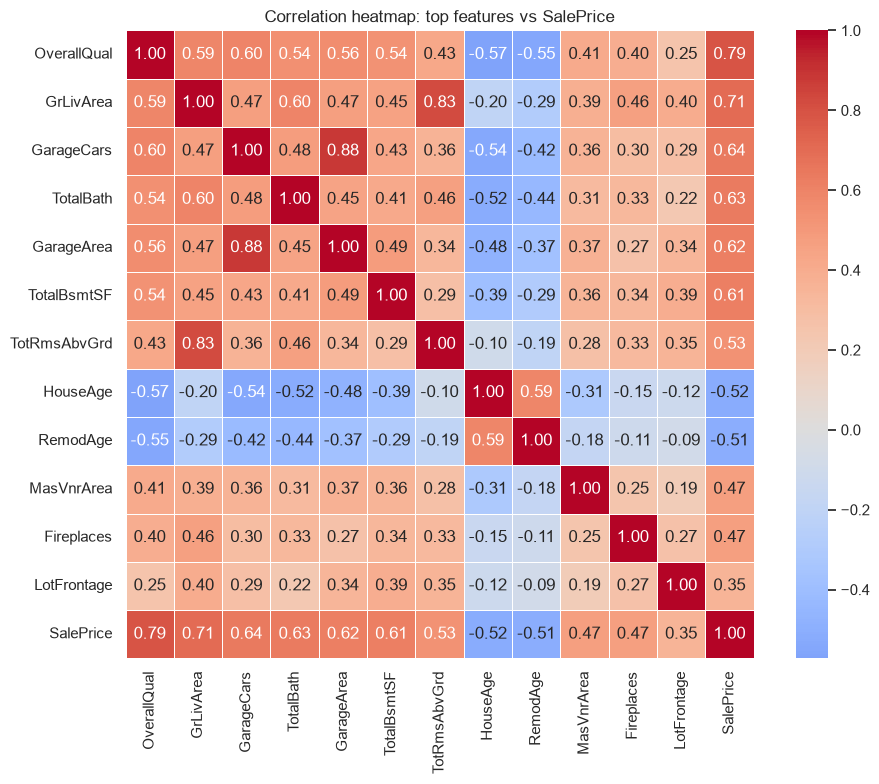

In [8]:
corr_df = data[num_cols + ["SalePrice"]]
corr = corr_df.corr()

top_corr = corr["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)
print("Top 10 numeric features by |correlation| with SalePrice:")
print(top_corr.head(10).round(3))

# Heatmap of the 12 features most correlated with price
top_features = top_corr.head(12).index.tolist() + ["SalePrice"]
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5)
plt.title("Correlation heatmap: top features vs SalePrice")
plt.tight_layout()
plt.show()

**Takeaway:** `OverallQual` (build quality) and `GrLivArea` (living area) correlate most strongly with price, followed by garage size (`GarageCars`, `GarageArea`), basement area and bathrooms. Note that `GarageCars` and `GarageArea` are correlated with each other (multicollinearity), so individual coefficients for such pairs should be interpreted with care. Correlation only covers numeric features. `Neighborhood` and other categories are assessed through the model coefficients in section 9.

## 5. Train / test split (80/20)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 1168 rows | Test: 292 rows


## 6. Train the Linear Regression model

In [10]:
lin_model = Pipeline([("prep", make_preprocessor()),
                      ("model", LinearRegression())])
lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
print("Model trained. Number of encoded features:",
      lin_model.named_steps["prep"].transform(X_test).shape[1])

Model trained. Number of encoded features: 194


## 7. Evaluate the model: MSE, RMSE, R²

In [11]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    rows = {}
    for label, X_, y_ in [("Train", X_tr, y_tr), ("Test", X_te, y_te)]:
        pred = model.predict(X_)
        mse = mean_squared_error(y_, pred)
        rows[label] = {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_, pred)}
    out = pd.DataFrame(rows).T
    out.insert(0, "Model", name)
    return out

lin_results = evaluate("Linear Regression", lin_model, X_train, y_train, X_test, y_test)
lin_results.style.format({"MSE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"})

,Model,MSE,RMSE,R2
Train,Linear Regression,"615,237,072","24,804",0.8969
Test,Linear Regression,"986,285,680","31,405",0.8714


In [12]:
test_rmse = lin_results.loc["Test", "RMSE"]
test_r2 = lin_results.loc["Test", "R2"]
print(f"Test R²   : {test_r2:.3f}  -> the model explains {test_r2*100:.1f}% of the variance in house prices")
print(f"Test RMSE : {test_rmse:,.0f}  -> typical prediction error in price units")
print(f"Average price: {y.mean():,.0f}  -> RMSE is ~{test_rmse / y.mean() * 100:.0f}% of the average price")

Test R²   : 0.871  -> the model explains 87.1% of the variance in house prices
Test RMSE : 31,405  -> typical prediction error in price units
Average price: 180,921  -> RMSE is ~17% of the average price


## 8. Diagnostic plots

### 8.1 Actual vs predicted prices

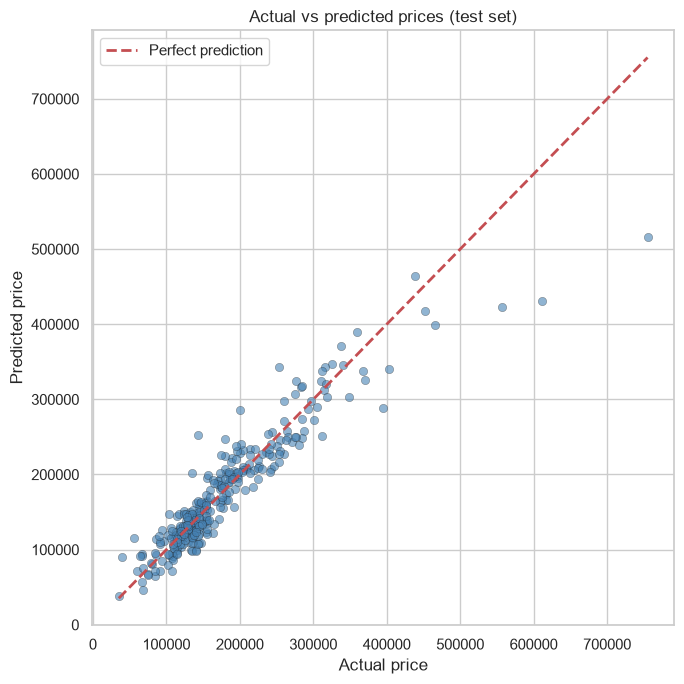

In [13]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor="k", linewidth=0.3, color="steelblue")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", lw=2, label="Perfect prediction")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted prices (test set)")
plt.legend()
plt.tight_layout()
plt.show()

Points hugging the red diagonal mean accurate predictions. The fit is tight for typical houses (roughly 100k to 300k). The most expensive houses (above about 400k) are clearly **under-predicted**: a linear model struggles to reach the extreme high end of a right-skewed price distribution.

### 8.2 Residual plots

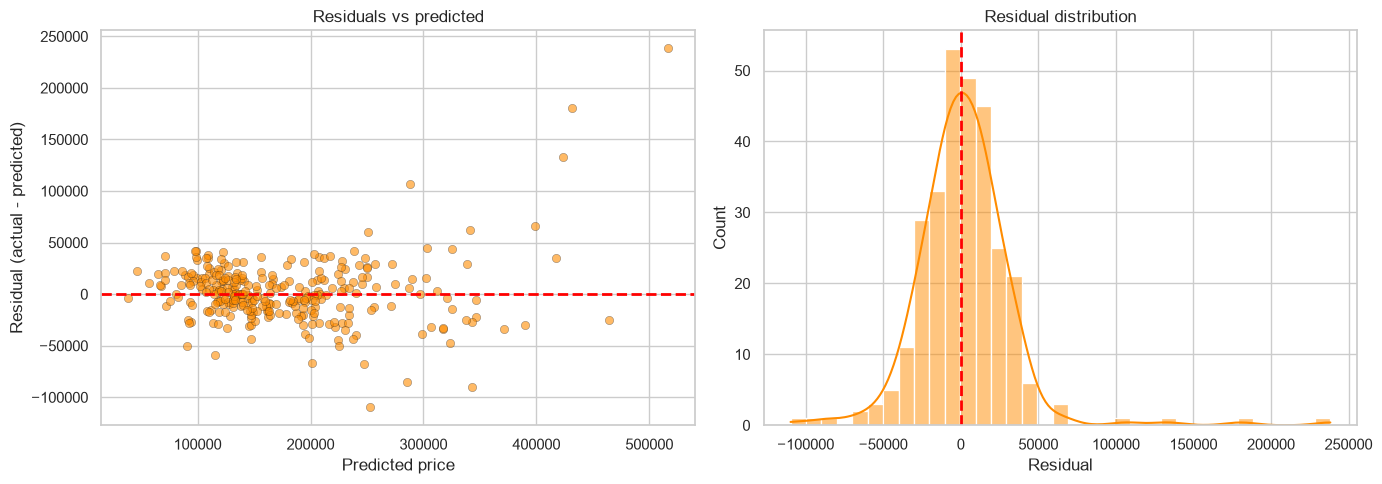

Mean residual: 2,028 (should be close to 0)


In [14]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred, residuals, alpha=0.6, edgecolor="k", linewidth=0.3, color="darkorange")
axes[0].axhline(0, color="red", ls="--", lw=2)
axes[0].set_xlabel("Predicted price")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted")

sns.histplot(residuals, kde=True, ax=axes[1], color="darkorange")
axes[1].axvline(0, color="red", ls="--", lw=2)
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Residual")
plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():,.0f} (should be close to 0)")

**Interpretation:** residuals are centred near zero and mostly scattered randomly, which is what we want. Two imperfections remain: the spread widens at higher predicted prices (mild heteroscedasticity) and there are a few large outliers, mostly expensive homes. Both are typical for skewed price data. A common fix, outside this task's scope, is to model `log(price)`.

## 9. Coefficient analysis

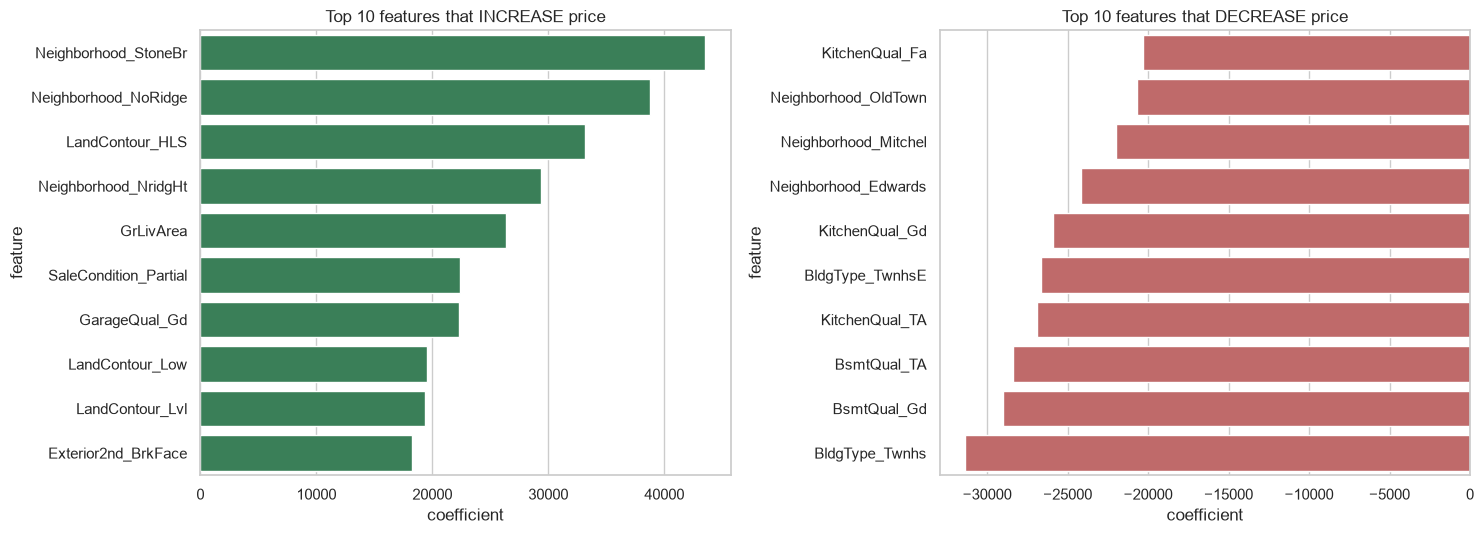

Top 10 positive coefficients:


,feature,coefficient
0,Neighborhood_StoneBr,43530.0
1,Neighborhood_NoRidge,38768.0
2,LandContour_HLS,33144.0
3,Neighborhood_NridgHt,29352.0
4,GrLivArea,26366.0
5,SaleCondition_Partial,22362.0
6,GarageQual_Gd,22255.0
7,LandContour_Low,19550.0
8,LandContour_Lvl,19393.0
9,Exterior2nd_BrkFace,18225.0


Top 10 negative coefficients:


,feature,coefficient
0,BldgType_Twnhs,-31373.0
1,BsmtQual_Gd,-29038.0
2,BsmtQual_TA,-28385.0
3,KitchenQual_TA,-26888.0
4,BldgType_TwnhsE,-26633.0
5,KitchenQual_Gd,-25895.0
6,Neighborhood_Edwards,-24199.0
7,Neighborhood_Mitchel,-21984.0
8,Neighborhood_OldTown,-20722.0
9,KitchenQual_Fa,-20329.0


In [15]:
prep = lin_model.named_steps["prep"]
feature_names = prep.get_feature_names_out()
feature_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

coef_df = pd.DataFrame({"feature": feature_names,
                        "coefficient": lin_model.named_steps["model"].coef_})
# Pooled "infrequent" groups are bags of unrelated rare categories, so they are not
# interpretable as a single feature. They stay in the model but are left out of the ranking.
coef_df = coef_df[~coef_df["feature"].str.contains("infrequent")]
coef_df = coef_df.sort_values("coefficient", ascending=False)

top_pos = coef_df.head(10)
top_neg = coef_df.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=top_pos, y="feature", x="coefficient", ax=axes[0], color="seagreen")
axes[0].set_title("Top 10 features that INCREASE price")
sns.barplot(data=top_neg, y="feature", x="coefficient", ax=axes[1], color="indianred")
axes[1].set_title("Top 10 features that DECREASE price")
plt.tight_layout()
plt.show()

print("Top 10 positive coefficients:")
display(top_pos[["feature", "coefficient"]].round(0).reset_index(drop=True))
print("Top 10 negative coefficients:")
display(top_neg[["feature", "coefficient"]].round(0).sort_values("coefficient").reset_index(drop=True))

**How to read these:**
- **Numeric features** were standardised, so a coefficient is the price change for a +1 standard deviation increase in that feature, holding everything else constant (for example, `GrLivArea` or `OverallQual`).
- **One-hot features** such as `Neighborhood_StoneBr` show the price premium or discount versus the dropped reference category of that column (the alphabetically first level). That is why `BsmtQual_Gd` or `KitchenQual_TA` are negative: they are compared with the best level, `Ex` (excellent). Read them as "this quality level sells for less than excellent", not as "good kitchens hurt prices".
- Among **numeric** features, living area (`GrLivArea`) has by far the largest effect, followed by `OverallQual` and `GarageCars`; `HouseAge` is negative (older houses sell for less). `TotalBsmtSF` shows a small negative coefficient only because it overlaps with `GrLivArea` and other size features (multicollinearity), so do not read it as "bigger basements lower the price". Premium neighbourhoods (`StoneBr`, `NoRidge`, `NridgHt`) add the largest location premiums, and `Partial` sales (new builds) sell for more.
- Pooled rare categories (`*_infrequent_sklearn`) are excluded from the ranking because each is a mix of unrelated rare levels. Coefficients on small categories can still be noisy, and related features overlap (multicollinearity), which is one reason the regularised models below can generalise better.

## 10. (Bonus) Linear Regression vs Ridge vs Lasso

Regularisation penalises large coefficients, which tames overfitting from the ~200 encoded features. The penalty strength (`alpha`) is chosen by 5-fold cross-validation on the **training** data only.

In [16]:
ridge_model = Pipeline([("prep", make_preprocessor()),
                        ("model", RidgeCV(alphas=np.logspace(-2, 3, 40), cv=5))])
lasso_model = Pipeline([("prep", make_preprocessor()),
                        ("model", LassoCV(alphas=np.logspace(0, 4, 40), cv=5,
                                          max_iter=100000, random_state=RANDOM_STATE))])
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

print(f"Best Ridge alpha: {ridge_model.named_steps['model'].alpha_:.2f}")
print(f"Best Lasso alpha: {lasso_model.named_steps['model'].alpha_:.2f}")

comparison = pd.concat([
    evaluate("Linear Regression", lin_model, X_train, y_train, X_test, y_test),
    evaluate("Ridge", ridge_model, X_train, y_train, X_test, y_test),
    evaluate("Lasso", lasso_model, X_train, y_train, X_test, y_test),
]).reset_index().rename(columns={"index": "Set"})

comparison.style.format({"MSE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"})

Best Ridge alpha: 16.04
Best Lasso alpha: 142.51


,Set,Model,MSE,RMSE,R2
0,Train,Linear Regression,"615,237,072","24,804",0.8969
1,Test,Linear Regression,"986,285,680","31,405",0.8714
2,Train,Ridge,"686,646,408","26,204",0.8849
3,Test,Ridge,"969,983,965","31,145",0.8735
4,Train,Lasso,"706,194,522","26,574",0.8816
5,Test,Lasso,"959,274,463","30,972",0.8749


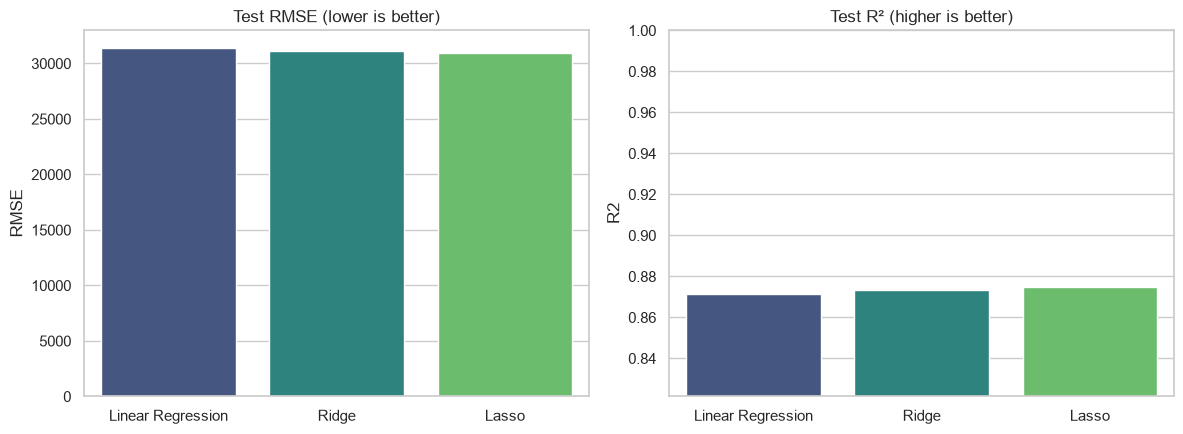

Lasso kept 98 of 194 features (set 96 to exactly zero)

Best test RMSE: Lasso (30,972)


In [17]:
test_cmp = comparison[comparison["Set"] == "Test"].set_index("Model")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=test_cmp.index, y=test_cmp["RMSE"], ax=axes[0], palette="viridis")
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_xlabel("")
sns.barplot(x=test_cmp.index, y=test_cmp["R2"], ax=axes[1], palette="viridis")
axes[1].set_title("Test R² (higher is better)")
axes[1].set_xlabel("")
axes[1].set_ylim(test_cmp["R2"].min() - 0.05, 1)
plt.tight_layout()
plt.show()

lasso_coefs = lasso_model.named_steps["model"].coef_
print(f"Lasso kept {np.sum(lasso_coefs != 0)} of {len(lasso_coefs)} features "
      f"(set {np.sum(lasso_coefs == 0)} to exactly zero)")

best = test_cmp["RMSE"].idxmin()
print(f"\nBest test RMSE: {best} ({test_cmp.loc[best, 'RMSE']:,.0f})")

**Conclusion**
- Plain Linear Regression is a solid baseline, but with ~200 correlated encoded features it fits the training data better than the test data (compare the Train and Test rows above).
- **Ridge** shrinks coefficients smoothly; **Lasso** also performs feature selection by setting weak predictors to exactly zero, giving a simpler and easier-to-explain model. Compare the test RMSE and R² in the table above to see how much regularisation helps on this split.
- The key drivers of price are consistent across models: living area, overall quality, garage capacity, neighbourhood and house age.
- Remaining limitation: all three models under-predict the most expensive houses. Modelling `log(SalePrice)` or adding interaction terms are natural next steps.